# Hyperparameter Tuning in Python

    Nama  : Nuh Priyonggo

## Import Library

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder, OneHotEncoder, OrdinalEncoder
from sklearn.model_selection import train_test_split

from statsmodels.stats.outliers_influence import variance_inflation_factor as vif
from statsmodels.tools.tools import add_constant

from imblearn.over_sampling import SMOTE

from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from imblearn.pipeline import Pipeline

from sklearn.metrics import (
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

## 1. Persiapan Data + EDA

- Buka dataset Churn Prediction dan eksplorasi data yang tersedia.
- Identifikasi aspek penting seperti jumlah fitur, tipe data, serta distribusi target.
- Tangani potensi masalah seperti nilai yang hilang atau data yang tidak sesuai.

### Load .csv

In [ ]:
df = pd.read_csv('/content/churn.csv')

In [ ]:
df.head()

,customerID,Gender,SeniorCitizen,Partner,Dependents,Tenure,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0.0,NaN,No,1.0,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0.0,No,No,34.0,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0.0,No,No,2.0,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0.0,No,No,45.0,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0.0,No,No,2.0,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


### Dataset Info

In [ ]:
print(df.info())
print(f"\nShape: {df.shape}")

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7046 entries, 0 to 7045
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7037 non-null   object 
 1   Gender            7030 non-null   object 
 2   SeniorCitizen     7034 non-null   float64
 3   Partner           7030 non-null   object 
 4   Dependents        7027 non-null   object 
 5   Tenure            7029 non-null   float64
 6   Contract          7033 non-null   object 
 7   PaperlessBilling  7033 non-null   object 
 8   PaymentMethod     7035 non-null   object 
 9   MonthlyCharges    7036 non-null   float64
 10  TotalCharges      7046 non-null   float64
 11  Churn             7046 non-null   object 
dtypes: float64(4), object(8)
memory usage: 660.7+ KB
None

Shape: (7046, 12)


### Statistik Deskriptif

In [ ]:
df.describe(include='all')

,customerID,Gender,SeniorCitizen,Partner,Dependents,Tenure,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
count,7037,7030,7034.000000,7030,7027,7029.000000,7033,7033,7035,7036.000000,7046.000000,7046
unique,7023,2,NaN,2,2,NaN,3,2,4,NaN,NaN,2
top,3604-WLABM,Male,NaN,No,No,NaN,Month-to-month,Yes,Electronic check,NaN,NaN,No
freq,2,3552,NaN,3638,4931,NaN,3873,4168,2367,NaN,NaN,5174
mean,NaN,NaN,0.162354,NaN,NaN,32.412150,NaN,NaN,NaN,64.800391,2281.921636,NaN
std,NaN,NaN,0.368802,NaN,NaN,24.546806,NaN,NaN,NaN,30.070620,2265.653438,NaN
min,NaN,NaN,0.000000,NaN,NaN,1.000000,NaN,NaN,NaN,18.250000,18.800000,NaN
25%,NaN,NaN,0.000000,NaN,NaN,9.000000,NaN,NaN,NaN,35.650000,401.350000,NaN
50%,NaN,NaN,0.000000,NaN,NaN,29.000000,NaN,NaN,NaN,70.350000,1397.100000,NaN
75%,NaN,NaN,0.000000,NaN,NaN,55.000000,NaN,NaN,NaN,89.850000,3791.000000,NaN


### Cek Missing Values

In [ ]:
print(df.isnull().sum())

customerID           9
Gender              16
SeniorCitizen       12
Partner             16
Dependents          19
Tenure              17
Contract            13
PaperlessBilling    13
PaymentMethod       11
MonthlyCharges      10
TotalCharges         0
Churn                0
dtype: int64


### Cek Duplicates

In [ ]:
df.duplicated().sum()

np.int64(14)

### Insight Eksplorasi Data Awal:

- Dataset ini berisi data customer churn yang terdiri dari 7046 baris data dan 12 kolom.
- Kolom `customerID` merupakan identifier sehingga tidak akan digunakan. Kolom `Gender` juga tidak akan digunakan dalam tujuan machine learning untuk klasifikasi customer churn.
- Terdapat missing values pada hampir semua kolom dan terdapat data yang duplikat.
- Perlu dilakukan encoding untuk data kategorikal yang masih berupa object.
- Target = `Churn`

### Data Cleaning

In [ ]:
df_clean = df.copy()

#### Hapus Kolom yang Tidak Terpakai

In [ ]:
df_clean = df_clean.drop(columns=['customerID', 'Gender'])

#### Handle Duplicates

Hapus baris yang duplikat

In [ ]:
df_clean = df_clean.drop_duplicates()

#### Handle Missing Values

Hapus baris yang memiliki missing value

In [ ]:
df_clean = df_clean.dropna()

#### Validasi Ulang Data

In [ ]:
print(df_clean.isnull().sum())

SeniorCitizen       0
Partner             0
Dependents          0
Tenure              0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64


In [ ]:
df_clean.duplicated().sum()

np.int64(0)

In [ ]:
before = len(df)
after = len(df_clean)

lost = before - after
lost_percentage = (lost / before) * 100

print(f"Data awal       : {before}")
print(f"Data setelah    : {after}")
print(f"Data yang hilang: {lost}")
print(f"Persentase hilang: {lost_percentage:.2f}%")

Data awal       : 7046
Data setelah    : 6879
Data yang hilang: 167
Persentase hilang: 2.37%


In [ ]:
print("Sebelum:")
print(df['Churn'].value_counts(normalize=True) * 100)

print("\nSesudah:")
print(df_clean['Churn'].value_counts(normalize=True) * 100)

Sebelum:
Churn
No     73.431734
Yes    26.568266
Name: proportion, dtype: float64

Sesudah:
Churn
No     73.71711
Yes    26.28289
Name: proportion, dtype: float64


Data yang hilang sebanyak 167 baris atau 2.37% dari total data di mana angka tersebut masih di bawah 10% dan dapat diterima. Data yang dihapus juga tidak memberikan dampak yang signifikan untuk distribusi dari `Churn`.

#### 4. Pengolahan Data Kategorikal


- Teliti fitur kategorikal dalam dataset dan pilih metode transformasi yang sesuai.
- Uji berbagai pendekatan encoding untuk meningkatkan performa model.

Untuk fitur kategorikal biner, digunakan LabelEncoder karena fitur hanya memiliki dua kategori sehingga dapat direpresentasikan menjadi nilai 0 dan 1. Metode ini digunakan pada fitur `Partner`, `Dependents`, `PaperlessBilling`, dan `Churn`.

Fitur `Contract` menggunakan OrdinalEncoder karena kategorinya memiliki tingkatan berdasarkan lama kontrak, yaitu Month-to-month, One year, dan Two year.

Sementara itu, `PaymentMethod` menggunakan One-Hot Encoding karena memiliki beberapa kategori dan tidak memiliki urutan atau tingkatan yang bermakna.

In [ ]:
df_encoded = df_clean.copy()

##### Binary Encoding

In [ ]:
# Identifikasi kolom kategorikal yang masih berupa object
cat_cols = df_encoded.select_dtypes(include='object').columns.tolist()

# Kolom biner
binary_cols = [c for c in cat_cols if df_encoded[c].nunique() == 2]
print("Kolom biner:", binary_cols)

Kolom biner: ['Partner', 'Dependents', 'PaperlessBilling', 'Churn']


In [ ]:
le = LabelEncoder()
for col in binary_cols:
    df_encoded[col] = le.fit_transform(df_encoded[col])

Hasil:

In [ ]:
df_encoded.head()

,SeniorCitizen,Partner,Dependents,Tenure,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
1,0.0,0,0,34.0,One year,0,Mailed check,56.95,1889.50,0
2,0.0,0,0,2.0,Month-to-month,1,Mailed check,53.85,108.15,1
3,0.0,0,0,45.0,One year,0,Bank transfer (automatic),42.30,1840.75,0
4,0.0,0,0,2.0,Month-to-month,1,Electronic check,70.70,151.65,1
5,0.0,0,0,8.0,Month-to-month,1,Electronic check,99.65,820.50,1


##### Ordinal Encoding untuk `Contract` karena memiliki urutan

In [ ]:
contract_order = [['Month-to-month', 'One year', 'Two year']]
ordinal_encoder = OrdinalEncoder(categories=contract_order)
df_encoded['Contract'] = ordinal_encoder.fit_transform(df_encoded[['Contract']])

Hasil:

In [ ]:
df_encoded.head()

,SeniorCitizen,Partner,Dependents,Tenure,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
1,0.0,0,0,34.0,1.0,0,Mailed check,56.95,1889.50,0
2,0.0,0,0,2.0,0.0,1,Mailed check,53.85,108.15,1
3,0.0,0,0,45.0,1.0,0,Bank transfer (automatic),42.30,1840.75,0
4,0.0,0,0,2.0,0.0,1,Electronic check,70.70,151.65,1
5,0.0,0,0,8.0,0.0,1,Electronic check,99.65,820.50,1


##### One-Hot Encoding untuk Kolom Nominal (Kategori > 2 dan tidak punya urutan)

In [ ]:
remaining_cat_cols = [c for c in df_encoded.select_dtypes(include='object').columns]
print("Kolom Nominal:", remaining_cat_cols)

Kolom Nominal: ['PaymentMethod']


In [ ]:
df_encoded = pd.get_dummies(df_encoded, columns=remaining_cat_cols, drop_first=True)

Hasil:

In [ ]:
df_encoded.head()

,SeniorCitizen,Partner,Dependents,Tenure,Contract,PaperlessBilling,MonthlyCharges,TotalCharges,Churn,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
1,0.0,0,0,34.0,1.0,0,56.95,1889.50,0,False,False,True
2,0.0,0,0,2.0,0.0,1,53.85,108.15,1,False,False,True
3,0.0,0,0,45.0,1.0,0,42.30,1840.75,0,False,False,False
4,0.0,0,0,2.0,0.0,1,70.70,151.65,1,False,True,False
5,0.0,0,0,8.0,0.0,1,99.65,820.50,1,False,True,False


#### Validasi Ulang Data

In [ ]:
print("Shape: ", df_encoded.shape)
df_encoded.info()

Shape:  (6879, 12)
<class 'pandas.core.frame.DataFrame'>
Index: 6879 entries, 1 to 7031
Data columns (total 12 columns):
 #   Column                                 Non-Null Count  Dtype  
---  ------                                 --------------  -----  
 0   SeniorCitizen                          6879 non-null   float64
 1   Partner                                6879 non-null   int64  
 2   Dependents                             6879 non-null   int64  
 3   Tenure                                 6879 non-null   float64
 4   Contract                               6879 non-null   float64
 5   PaperlessBilling                       6879 non-null   int64  
 6   MonthlyCharges                         6879 non-null   float64
 7   TotalCharges                           6879 non-null   float64
 8   Churn                                  6879 non-null   int64  
 9   PaymentMethod_Credit card (automatic)  6879 non-null   bool   
 10  PaymentMethod_Electronic check         6879 non-null   boo

In [ ]:
df_encoded.describe().T

,count,mean,std,min,25%,50%,75%,max
SeniorCitizen,6879.0,0.162378,0.368824,0.00,0.00,0.0,0.000,1.00
Partner,6879.0,0.484954,0.499810,0.00,0.00,0.0,1.000,1.00
Dependents,6879.0,0.299898,0.458246,0.00,0.00,0.0,1.000,1.00
Tenure,6879.0,32.628289,24.487140,1.00,9.00,29.0,56.000,72.00
Contract,6879.0,0.693269,0.834067,0.00,0.00,0.0,1.000,2.00
PaperlessBilling,6879.0,0.593109,0.491290,0.00,0.00,1.0,1.000,1.00
MonthlyCharges,6879.0,64.995850,30.050370,18.25,35.85,70.5,89.950,118.75
TotalCharges,6879.0,2298.615867,2265.167569,18.80,415.00,1414.2,3834.175,8684.80
Churn,6879.0,0.262829,0.440202,0.00,0.00,0.0,1.000,1.00


Data sudah bersih dan siap digunakan untuk proses selanjutnya.

### Visualisasi Data

#### Distribusi Kolom Numerik

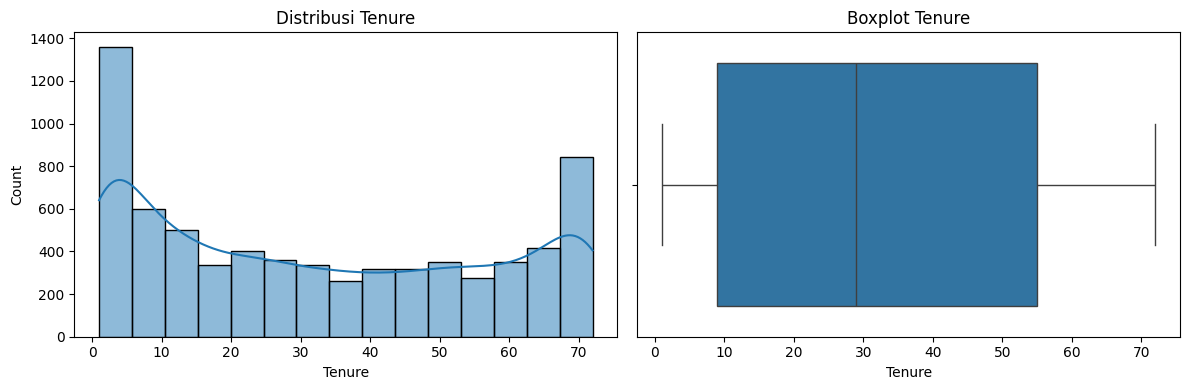

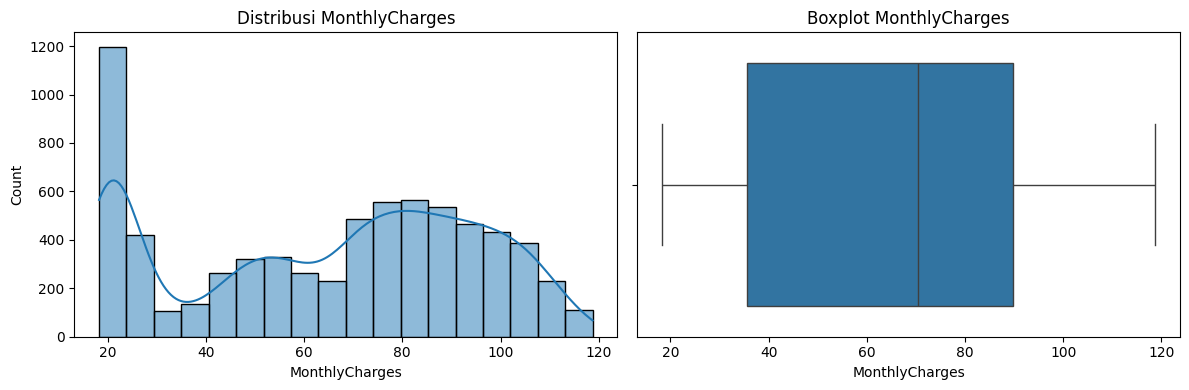

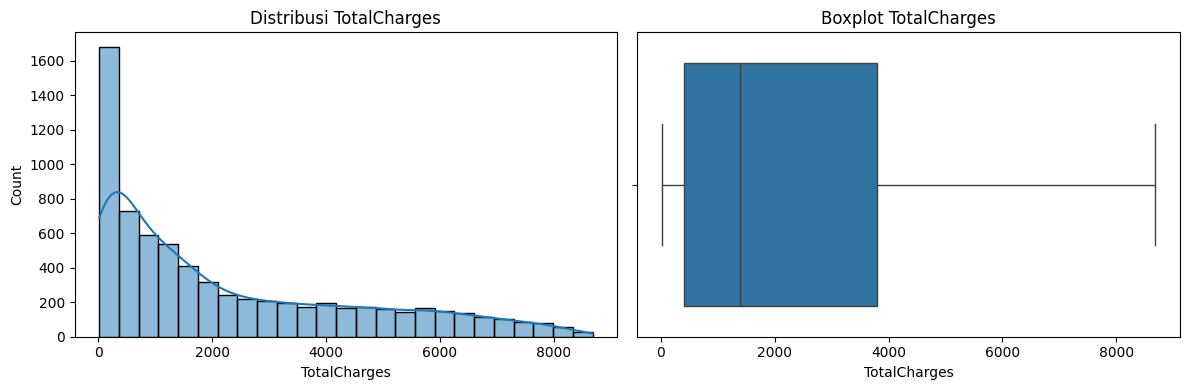

In [ ]:
kolom = ['Tenure', 'MonthlyCharges', 'TotalCharges']

for col in kolom:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    sns.histplot(
        data=df,
        x=col,
        kde=True,
        ax=axes[0]
    )

    axes[0].set_title(f'Distribusi {col}')

    sns.boxplot(
        data=df,
        x=col,
        ax=axes[1]
    )

    axes[1].set_title(f'Boxplot {col}')

    plt.tight_layout()
    plt.show()

Berdasarkan Boxplot, untuk semua data tidak memiliki nilai ekstrem atau outlier.

1. `Tenure Months`: Berdasarkan plot, dapat terlihat bahwa adanya konsentrasi jumlah pelanggan yang berada di bulan awal dan bulan akhir.
2. `Monthly Charges`: Persebaran data tidak seimbang, kebanyakan pelanggan memiliki tagihan di angka sekitar 20. Plot juga menunjukkan adanya perbedaan biaya layanan antar perlanggan.
3. `Total Charges`: Dari histplot terlihat distribusinya cenderung right skewed dimana pelanggan kebanyakan memiliki total pembayaran yang relatif rendah.

#### Distribusi Churn

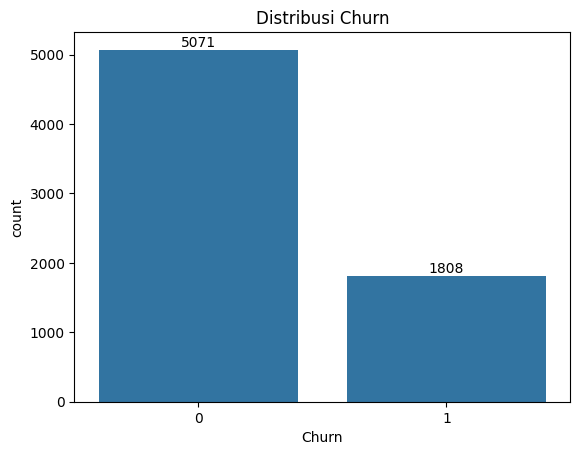

In [ ]:
ax = sns.countplot(data=df_encoded, x='Churn')

plt.title('Distribusi Churn')
ax.bar_label(ax.containers[0])

plt.show()

Data target tidak balance sehingga akan dilakukan handling imbalance dengan sampling.

## 2. Pembagian Dataset

- Tentukan strategi pembagian dataset yang tepat untuk training, validasi, dan testing.
- Pastikan dataset mencerminkan distribusi yang seimbang untuk menghasilkan model yang andal.

### Pisahkan Fitur dan Target

In [ ]:
X = df_encoded.drop(columns='Churn')
y = df_encoded['Churn']

In [ ]:
print(f"Fitur: {X.shape}")
print(f"Target: {y.shape}")

Fitur: (6879, 11)
Target: (6879,)


### Split Pretrain dan Test

In [ ]:
X_pretrain, X_test, y_pretrain, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42) # pretrain 80 : 20 test

### Split Train dan Validation

In [ ]:
X_train, X_valid, y_train, y_valid = train_test_split(
    X_pretrain, y_pretrain, test_size=0.2, random_state=42) # train 80:20 validation

### Cek Train-Validation-Test

In [ ]:
print(f"Train: {len(X_train)}\nValidation: {len(X_valid)}\nTest: {len(X_test)}")

Train: 4402
Validation: 1101
Test: 1376


## 3. Analisis Korelasi dan Seleksi Fitur

- Analisis hubungan antar fitur dalam dataset untuk memahami potensi multicollinearity.
- Identifikasi dan pilih fitur yang paling relevan untuk model berdasarkan analisis yang dilakukan.

### Correlation Heatmap

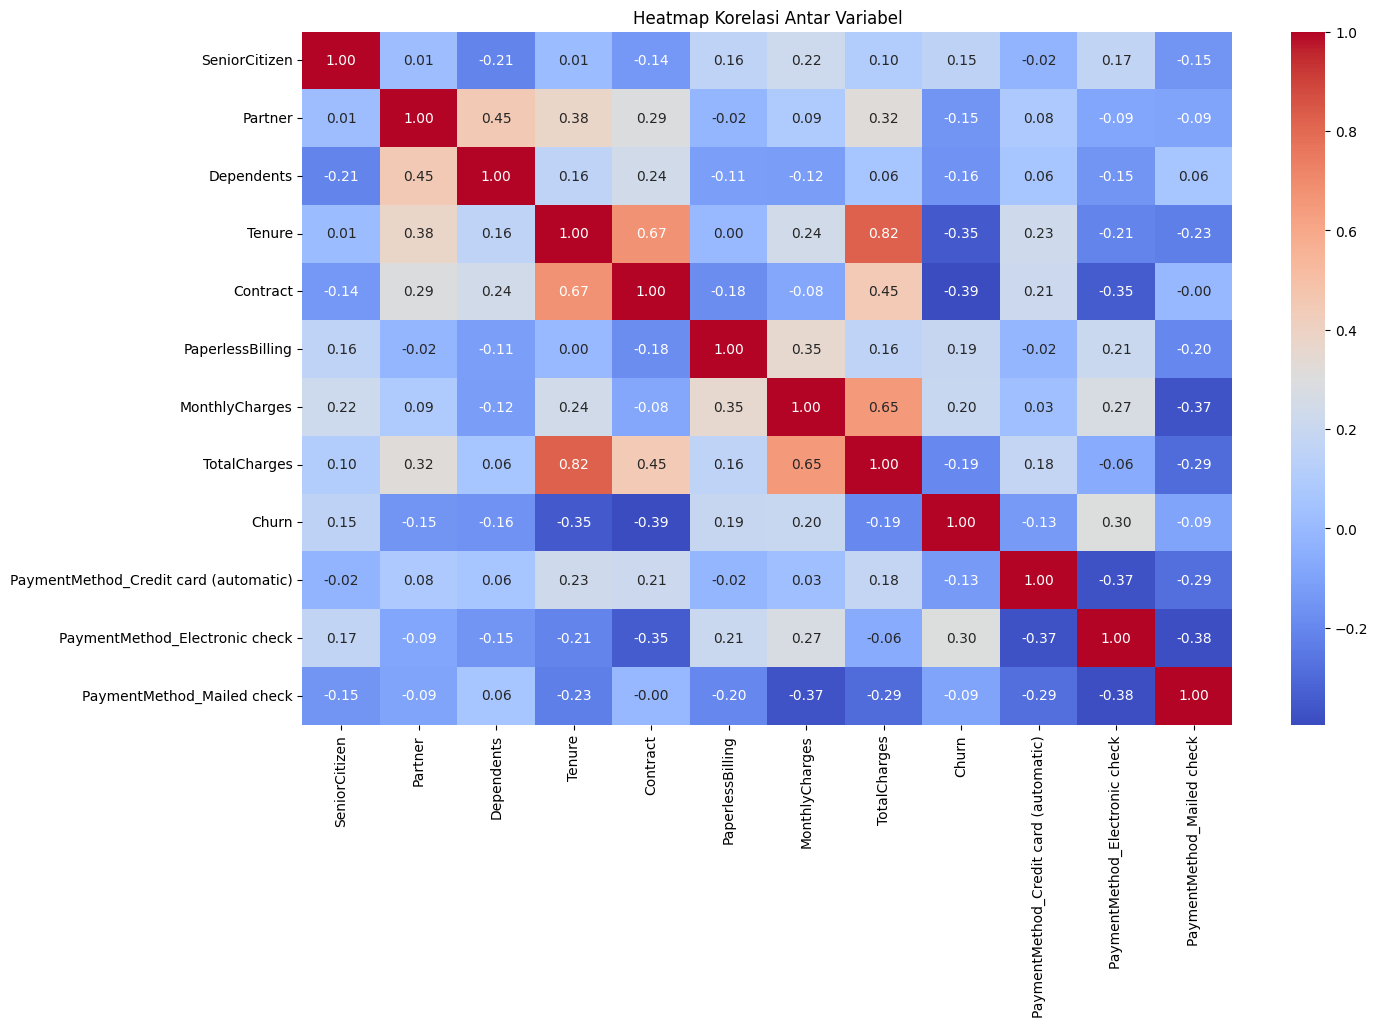

In [ ]:
corr = df_encoded.corr()

plt.figure(figsize=(15, 9))

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Heatmap Korelasi Antar Variabel")
plt.show()

Berdasarkan correlation plot, terdapat beberapa hubungan yang dapat dicek untuk potensi adanya multicollinearity, fitur tersebut adalah:
- `Tenure` - `TotalCharges`: 0.82
- `Tenure` - `Contract`: 0.67
- `MonthlyCharges` - `TotalCharges`: 0.65

### Cek VIF Sebelum Seleksi Fitur

In [ ]:
X = add_constant(X_train)

vif_df = pd.DataFrame([vif(X.values, i)
               for i in range(X.shape[1])],
              index=X.columns).reset_index()
vif_df.columns = ['feature','vif_score']
vif_df = vif_df.loc[vif_df.feature!='const']

In [ ]:
print(vif_df)

                                  feature  vif_score
1                           SeniorCitizen   1.128462
2                                 Partner   1.446776
3                              Dependents   1.353987
4                                  Tenure   7.585874
5                                Contract   2.227412
6                        PaperlessBilling   1.197777
7                          MonthlyCharges   4.068429
8                            TotalCharges  10.036160
9   PaymentMethod_Credit card (automatic)   1.562173
10         PaymentMethod_Electronic check   1.954840
11             PaymentMethod_Mailed check   1.853579


Dari hasil perhitungan VIF, terlihat bahwa fitur yang memiliki score tinggi (VIF > 5) adalah:
- `TotalCharges` = 10.03
- `Tenure` = 7.58

### Seleksi Fitur

Berdasarkan hasil VIF, fitur yang dipertahankan adalah `Tenure`, sedangkan `TotalCharges` akan didrop.

In [ ]:
X_train_selected = X_train.drop(columns = 'TotalCharges')

### VIF Setelah Seleksi Fitur

In [ ]:
X = add_constant(X_train_selected)

vif_df = pd.DataFrame([vif(X.values, i)
               for i in range(X.shape[1])],
              index=X.columns).reset_index()
vif_df.columns = ['feature','vif_score']
vif_df = vif_df.loc[vif_df.feature!='const']

In [ ]:
print(vif_df)

                                  feature  vif_score
1                           SeniorCitizen   1.128387
2                                 Partner   1.446766
3                              Dependents   1.353898
4                                  Tenure   2.478172
5                                Contract   2.227152
6                        PaperlessBilling   1.196664
7                          MonthlyCharges   1.475913
8   PaymentMethod_Credit card (automatic)   1.561390
9          PaymentMethod_Electronic check   1.948059
10             PaymentMethod_Mailed check   1.827434


Setelah `TotalCharges` didrop, nilai VIF dari `Tenure` turun menjadi 2.47 dan fitur lainnya tetap berada dibawah 5, sehingga dari seleksi fitur ini berhasil menghandle masalah multicollinearity.

## 5. Pemilihan Metrik Evaluasi

Pada dataset ini akan dilakukan klasifikasi untuk pelanggan yang churn atau tidak. Sesuai dengan kebutuhan bisnis, metrik utama yang akan dipakai adalah **Recall** untuk mengidentifikasi sebanyak mungkin pelanggan yang benar-benar melakukan churn.

Recall yang rendah menunjukkan bahwa masih banyak pelanggan yang sebenarnya churn tetapi gagal teridentifikasi oleh model (False Negative). Ini perlu diperhatikan karena False Negative dapat merugikan perusahaan.

Selain Recall, digunakan beberapa metrik pendukung:

- Accuracy digunakan untuk melihat proporsi seluruh prediksi yang berhasil diklasifikasikan dengan benar.
- Precision digunakan untuk melihat seberapa tepat prediksi churn yang diberikan oleh model.
- F1-Score digunakan untuk melihat keseimbangan antara Precision dan Recall.
- Confusion Matrix digunakan untuk melihat jumlah True Positive, True Negative, False Positive, dan False Negative secara lebih rinci.

## 6. Pelatihan Model dan Hyperparameter Tuning

- Pilih model machine learning yang sesuai dengan dataset.
- Lakukan eksperimen dengan berbagai kombinasi hyperparameter.
- Gunakan teknik validasi untuk membandingkan performa model dengan berbagai konfigurasi.

Model yang akan digunakan yang sesuai dengan dataset adalah RandomForestClassifier karena cocok untuk klasifikasi biner seperti churn, dapat menangani fitur numerik, dan tidak sensitif terhadap skala data, serta memiliki beberapa parameter yang dapat dituning.

### Drop kolom `TotalCharges`

In [ ]:
X_train = X_train_selected
X_valid = X_valid.drop(columns = 'TotalCharges')
X_test = X_test.drop(columns = 'TotalCharges')

### Cek Jumlah Data

In [ ]:
print("X_train :", X_train.shape)
print("X_valid :", X_valid.shape)
print("X_test  :", X_test.shape)

print("y_train :", y_train.shape)
print("y_valid :", y_valid.shape)
print("y_test  :", y_test.shape)

X_train : (4402, 10)
X_valid : (1101, 10)
X_test  : (1376, 10)
y_train : (4402,)
y_valid : (1101,)
y_test  : (1376,)


### Hyperparameter Tuning Menggunakan Optuna dengan Cross Validation

In [ ]:
!pip install optuna

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 442.4/442.4 kB 8.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 22.2 MB/s eta 0:00:00


In [ ]:
import optuna

In [ ]:
X = X_train
y = y_train

In [ ]:
cv = StratifiedKFold(
    n_splits=5, # 5 fold
    shuffle=True, # Acak data
    random_state=42 # Agar data konsisten untuk setiap iterasi
)

In [ ]:
for fold, (_, val_idx) in enumerate(cv.split(X, y), 1):
    y_fold = y.iloc[val_idx]

    print(f"Fold {fold}")
    print(y_fold.value_counts())
    print(y_fold.value_counts(normalize=True))
    print()

# Hanya untuk mengecek distribusi Churn di setiap fold

Fold 1
Churn
0    647
1    234
Name: count, dtype: int64
Churn
0    0.734393
1    0.265607
Name: proportion, dtype: float64

Fold 2
Churn
0    647
1    234
Name: count, dtype: int64
Churn
0    0.734393
1    0.265607
Name: proportion, dtype: float64

Fold 3
Churn
0    646
1    234
Name: count, dtype: int64
Churn
0    0.734091
1    0.265909
Name: proportion, dtype: float64

Fold 4
Churn
0    646
1    234
Name: count, dtype: int64
Churn
0    0.734091
1    0.265909
Name: proportion, dtype: float64

Fold 5
Churn
0    646
1    234
Name: count, dtype: int64
Churn
0    0.734091
1    0.265909
Name: proportion, dtype: float64



In [ ]:
def objective(trial):
    # Definisikan hiperparameter yang ingin dioptimalkan
    rf_params = {
        'n_estimators': trial.suggest_int('n_estimators', 100, 500),
        'max_depth': trial.suggest_int('max_depth', 5, 30),
        'min_samples_split': trial.suggest_int('min_samples_split', 2, 10),
        'min_samples_leaf': trial.suggest_int('min_samples_leaf', 1, 5),
        'max_features': trial.suggest_categorical(
            'max_features', ['sqrt', 'log2']
        ),
        'criterion': trial.suggest_categorical(
            'criterion', ['gini', 'entropy']
        )
    }

    # Buat model dengan hiperparameter yang dipilih
    model = Pipeline([
        ('smote', SMOTE(random_state=42)), # SMOTE dilakukan pada setiap fold, bukan pada keseluruhan data agar tidak terjadi data leakage
        ('rf', RandomForestClassifier(
            **rf_params,
            random_state=42,
            n_jobs=-1
        ))
    ])

    # Hitung skor cross-validation menggunakan hyperparameter yang dipilih
    scores = cross_val_score(model, X, y, cv=cv, scoring='recall')

    # Kembalikan rata-rata skor cross-validation sebagai nilai objektif
    return scores.mean()

In [ ]:
# Buat Optuna Study
study = optuna.create_study(direction='maximize')

# Jalankan proses optimasi
study.optimize(objective, n_trials=200)

# Dapatkan hasil terbaik
best_params = study.best_params
best_value = study.best_value
print(f"Best parameters: {best_params}")
print(f"Best value: {best_value}")

[I 2026-09-23 10:18:27,289] A new study created in memory with name: no-name-a741aced-a4f6-4544-a8ea-bc1f077a2dcb
[I 2026-09-23 10:18:38,807] Trial 0 finished with value: 0.6820512820512821 and parameters: {'n_estimators': 454, 'max_depth': 9, 'min_samples_split': 4, 'min_samples_leaf': 2, 'max_features': 'log2', 'criterion': 'gini'}. Best is trial 0 with value: 0.6820512820512821.
[I 2026-09-23 10:18:48,230] Trial 1 finished with value: 0.6538461538461539 and parameters: {'n_estimators': 317, 'max_depth': 21, 'min_samples_split': 10, 'min_samples_leaf': 5, 'max_features': 'log2', 'criterion': 'gini'}. Best is trial 0 with value: 0.6820512820512821.
[I 2026-09-23 10:19:02,271] Trial 2 finished with value: 0.6572649572649573 and parameters: {'n_estimators': 467, 'max_depth': 19, 'min_samples_split': 10, 'min_samples_leaf': 5, 'max_features': 'sqrt', 'criterion': 'gini'}. Best is trial 0 with value: 0.6820512820512821.
[I 2026-09-23 10:19:20,354] Trial 3 finished with value: 0.6358974358

Best parameters: {'n_estimators': 439, 'max_depth': 5, 'min_samples_split': 3, 'min_samples_leaf': 4, 'max_features': 'log2', 'criterion': 'gini'}
Best value: 0.7222222222222223


Hyperparameter tuning dengan Optuna menghasilkan parameter terbaik yaitu:
- n_estimators = 439
- max_depth = 5
- min_samples_split = 3
- min_samples_leaf = 4
- max_features = log2
- criterion = gini

### Inisialisasi Model

In [ ]:
baseline_model = Pipeline([ # Baseline model dengan default parameter
    ('smote', SMOTE(random_state=42)),
    ('rf', RandomForestClassifier(
        random_state=42,
        n_jobs=-1
    ))
])

In [ ]:
tuned_model = Pipeline([ # Tuned model dengan parameter hasil optuna
    ('smote', SMOTE(random_state=42)),
    ('rf', RandomForestClassifier(
        **best_params,
        random_state=42,
        n_jobs=-1
    ))
])

### Train Model

In [ ]:
baseline_model.fit(X_train, y_train)

Pipeline(steps=[('smote', SMOTE(random_state=42)),
                ('rf', RandomForestClassifier(n_jobs=-1, random_state=42))])

In [ ]:
tuned_model.fit(X_train, y_train)

Pipeline(steps=[('smote', SMOTE(random_state=42)),
                ('rf',
                 RandomForestClassifier(max_depth=5, max_features='log2',
                                        min_samples_leaf=4, min_samples_split=3,
                                        n_estimators=439, n_jobs=-1,
                                        random_state=42))])

### Evaluasi Pada Data Validation

In [ ]:
y_pred_valid_baseline = baseline_model.predict(X_valid)

In [ ]:
y_pred_valid_tuned = tuned_model.predict(X_valid)

In [ ]:
comparison = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1-Score'],
    'Baseline': [
        accuracy_score(y_valid, y_pred_valid_baseline),
        precision_score(y_valid, y_pred_valid_baseline),
        recall_score(y_valid, y_pred_valid_baseline),
        f1_score(y_valid, y_pred_valid_baseline)
    ],
    'Tuned': [
        accuracy_score(y_valid, y_pred_valid_tuned),
        precision_score(y_valid, y_pred_valid_tuned),
        recall_score(y_valid, y_pred_valid_tuned),
        f1_score(y_valid, y_pred_valid_tuned)
    ]
})

comparison

,Metric,Baseline,Tuned
0,Accuracy,0.773842,0.744777
1,Precision,0.568905,0.508685
2,Recall,0.559028,0.711806
3,F1-Score,0.563923,0.593343


In [ ]:
print("Peningkatan recall:",
      ((recall_score(y_valid, y_pred_valid_tuned) -
        recall_score(y_valid, y_pred_valid_baseline)) /
        recall_score(y_valid, y_pred_valid_baseline)) * 100, "%")

Peningkatan recall: 27.32919254658385 %


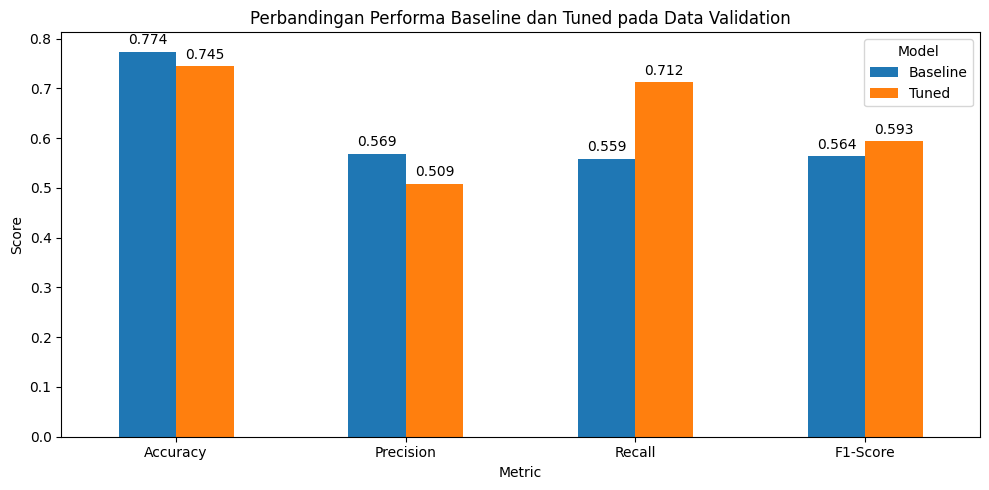

In [ ]:
ax = comparison.plot(
    x='Metric',
    y=['Baseline', 'Tuned'],
    kind='bar',
    figsize=(10, 5)
)

plt.title('Perbandingan Performa Baseline dan Tuned pada Data Validation')
plt.xlabel('Metric')
plt.ylabel('Score')
plt.xticks(rotation=0)
plt.legend(title='Model')

for container in ax.containers:
    ax.bar_label(container, fmt='%.3f', padding=3)

plt.tight_layout()
plt.show()

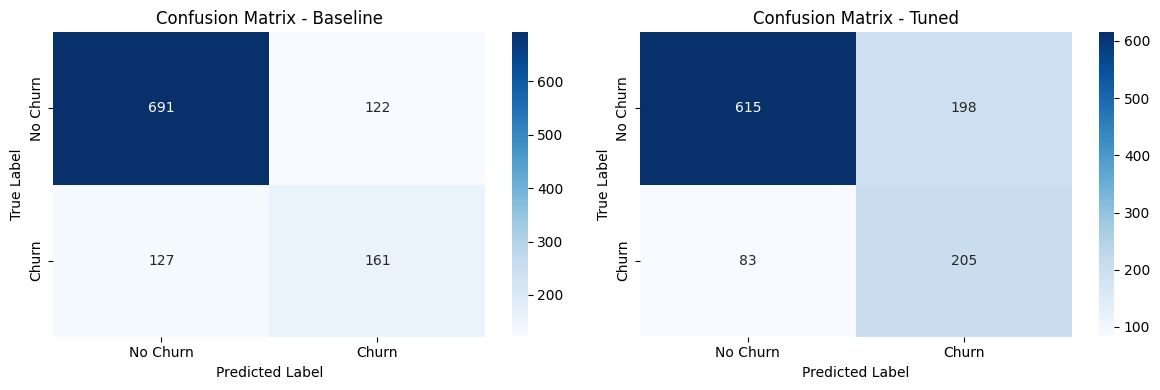

In [ ]:
cm_tuned = confusion_matrix(y_valid, y_pred_valid_tuned)
cm_baseline = confusion_matrix(y_valid, y_pred_valid_baseline)

labels = ['No Churn', 'Churn']

plt.figure(figsize=(12, 4))

# Baseline
plt.subplot(1, 2, 1)
sns.heatmap(
    cm_baseline,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=labels,
    yticklabels=labels
)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix - Baseline')

# Tuned
plt.subplot(1, 2, 2)
sns.heatmap(
    cm_tuned,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=labels,
    yticklabels=labels
)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix - Tuned')

plt.tight_layout()
plt.show()

Berdasarkan hasil evaluasi pada data validation, model dengan parameter terbaik dari hyperparameter tuning menghasilkan recall sebesar 0.7118, sedangkan pada model baseline menghasilkan recall sebesar 0.5590. Artinya model dengan parameter dari hyperparameter tuning berhasil dalam memaksimalkan nilai metrik evaluasi recall pada data ini dengan peningkatan relatif sebesar 27.33%.

Dalam confusion matrix juga terlihat, pada model baseline terdapat 127 False Negative dan 161 True Positive, sedangkan setelah tuning jumlah False Negative turun menjadi 83 dan True Positive meningkat menjadi 205. Hal ini menunjukkan bahwa model tuned berhasil mengidentifikasi lebih banyak pelanggan yang sebenarnya melakukan churn.

### Evaluasi Pada Data Test

In [ ]:
y_pred_test_tuned = best_model.predict(X_test)

In [ ]:
test_result = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1-Score'],
    'Tuned Test': [
        accuracy_score(y_test, y_pred_test_tuned),
        precision_score(y_test, y_pred_test_tuned),
        recall_score(y_test, y_pred_test_tuned),
        f1_score(y_test, y_pred_test_tuned)
    ]
})

test_result

,Metric,Tuned Test
0,Accuracy,0.740552
1,Precision,0.493097
2,Recall,0.714286
3,F1-Score,0.583431


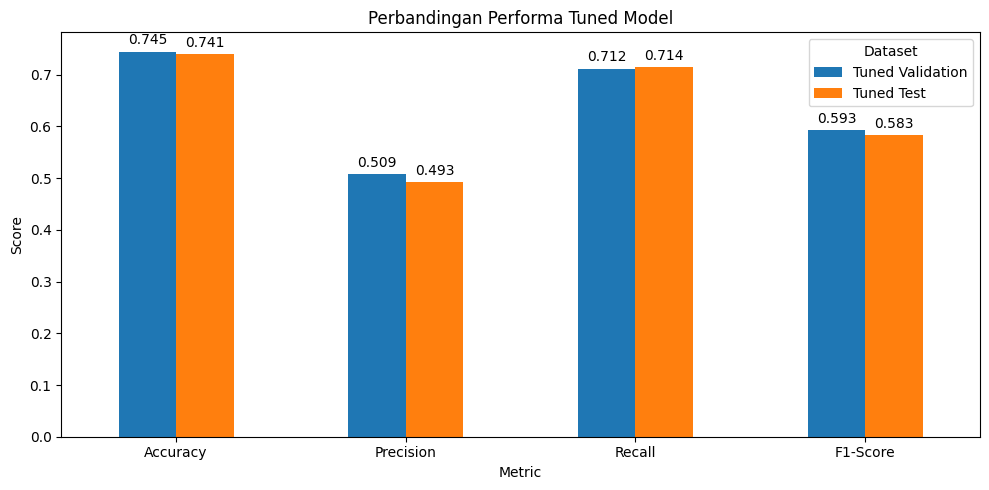

In [ ]:
validation_result = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1-Score'],
    'Tuned Validation': [
        accuracy_score(y_valid, y_pred_valid_tuned),
        precision_score(y_valid, y_pred_valid_tuned),
        recall_score(y_valid, y_pred_valid_tuned),
        f1_score(y_valid, y_pred_valid_tuned)
    ]
})

comparison_test = validation_result.merge(
    test_result,
    on='Metric'
)

ax = comparison_test.plot(
    x='Metric',
    y=['Tuned Validation', 'Tuned Test'],
    kind='bar',
    figsize=(10, 5)
)

plt.title('Perbandingan Performa Tuned Model')
plt.xlabel('Metric')
plt.ylabel('Score')
plt.xticks(rotation=0)
plt.legend(title='Dataset')

for container in ax.containers:
    ax.bar_label(container, fmt='%.3f', padding=3)

plt.tight_layout()
plt.show()

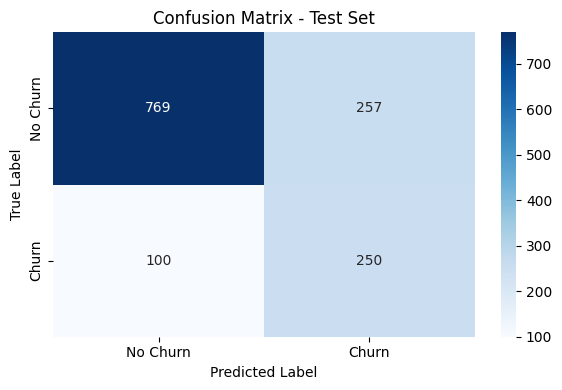

In [ ]:
cm_test = confusion_matrix(y_test, y_pred_test_tuned)

labels = ['No Churn', 'Churn']

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm_test,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=labels,
    yticklabels=labels
)

plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix - Test Set')

plt.tight_layout()
plt.show()

Berdasarkan hasil evaluasi pada data test, model tuned memperoleh Accuracy sebesar 74.06%, Precision sebesar 49.31%, Recall sebesar 71.43%, dan F1-Score sebesar 58.34%.

Recall menjadi metrik utama karena tujuan model adalah mengidentifikasi pelanggan yang berpotensi melakukan churn. Dari confusion matrix, terdapat 250 True Positive dan 100 False Negative. Artinya, dari 350 pelanggan yang sebenarnya melakukan churn, model berhasil mengidentifikasi 250 pelanggan atau sebesar 71.43%.

Hasil pada test set juga relatif konsisten dengan hasil validation set. Perbedaan pada setiap metrik relatif kecil, sehingga tidak terlihat adanya perubahan performa yang besar ketika model diterapkan pada data yang belum digunakan selama proses pengembangan.

Karena Recall ditetapkan sebagai emetrik utama pada permasalahan churn prediction, hasil tuning menunjukkan bahwa model menjadi lebih sensitif dalam mendeteksi pelanggan yang melakukan churn, dengan trade-off nya yaitu meningkatnya jumlah pelanggan yang diprediksi churn tetapi sebenarnya tidak churn (False Positive).

## Kesimpulan

Berdasarkan proses yang telah dilakukan, data churn dipersiapkan melalui proses pembersihan data, penghapusan data duplikat dan missing value, serta preprocessing fitur kategorikal. Kemudia feature selection dilakukan dengan melihat korelasi dan VIF.

Model Random Forest kemudian diterapkan dan dilakukan hyperparameter tuning yang berfokus untuk meningkatkan recall. Dalam hyperparameter tuning juga digunakan 5-fold cross validation dan SMOTE diterapkan di dalam pipeline sehingga proses sampling hanya dilakukan pada data training di setiap fold dan tidak memengaruhi validation maupun test set.

Hasil tuning menunjukkan bahwa Recall meningkat dari 55.90% pada model baseline menjadi 71.18% pada validation set, atau meningkat secara relatif sebesar 27.33%. Peningkatan Recall juga disertai penurunan False Negative dari 127 menjadi 83, sehingga lebih banyak pelanggan yang sebenarnya churn berhasil teridentifikasi. Tetapi, terdapat trade-off berupa peningkatan False Positive serta penurunan accuracy dan precision.

Pada evaluasi akhir menggunakan test set, diperoleh accuracy sebesar 74.06%, precision sebesar 49.31%, recall sebesar 71.43%, dan F1-Score sebesar 58.34% yang konsisten dengan evaluasi pada validation set.

Secara keseluruhan, proses hyperparameter tuning berhasil meningkatkan kemampuan model dalam mendeteksi pelanggan yang melakukan churn. Model tuned mampu mendapatkan Recall sekitar 71% pada data yang belum pernah digunakan selama proses pengembangan, meskipun peningkatan sensitivitas terhadap churn menyebabkan jumlah False Positive menjadi lebih tinggi.

## Reflection Questions

1. Mengapa penting melakukan persiapan data (data cleaning, analisis tipe data, dan pengecekan distribusi target) sebelum melatih model? Refleksikan bagaimana kualitas data dapat memengaruhi performa model churn prediction serta risiko apa yang terjadi jika model dilatih tanpa persiapan data yang tepat.
2. Bagaimana pemilihan fitur yang tepat (melalui analisis korelasi dan feature selection) dapat meningkatkan akurasi model sekaligus mengurangi overfitting? Jelaskan alasan mengapa pemahaman hubungan antar fitur penting untuk membangun model prediksi yang stabil dan dapat diandalkan.


Jawaban:

1. Persiapan data sebelum melatih model merupakan hal yang penting karena kualitas data sangat mempengaruhi hasil dari model dalam mempelajari pola churn. Tanpa adanya persiapan dan eksplorasi data, model dapat menghasilkan hasil evaluasi yang bias dan tidak tepat jika diinterpretasikan.Ketidakseimbangan target juga dapat menyebabkan model lebih cenderung memprediksi kelas mayoritas. Pada kasus churn prediction, kondisi tersebut dapat menyebabkan pelangan yang sebenarnya churn lebih banyak terlewat yang akan merugikan perusahaan. Oleh karena itu, data cleaning, pemeriksaan tipe data, analisis distribusi target, dan pengangannya diperlukan agar proses training menghasilkan model yang sesuai dengan tujuan prediksi.
2. Pemilihan fitur membantu mengurangi fitur yang redundan dan hubungan antar fitur yang terlalu kuat tanpa mengurangi informasi dataset. Pemahaman hubungan antar fitur adalah hal yang penting karena fitur yang redundan dapat membuat model mempelajari informasi yang sama sehingga meningkatkan kompleksitas model. Tujuan utama dari pemilihan fitur ini adalah supaya mempertahankan informasi yang relevan serta mengurangi kompleksitas, sehingga model memiliki representasi fitur yang sesuai untuk prediksi pada data baru sehingga dapat diandalkan.